# 07 · Accepted routers on your data: GraphRouter (ICLR 2025) and a RouterBench-style predictive router, vs your RL

**What this notebook does.** It runs two published routers on the *same* MMLU / MixInstruct tables, the *same* frozen DeBERTa features, the *same* test sets and the *same* cost (parameters / 7B) and utility as `05_multiseed_bandits_*.ipynb`, then compares them with your RL, HybridLLM and FrugalGPT results.

| Method | Source | Notes |
|---|---|---|
| **GraphRouter** | Feng, Shen, You, *ICLR 2025* | Heterogeneous graph (task / query / LLM nodes), 2-layer GNN, edge prediction. Re-implemented here in plain PyTorch following the paper's Eq. 1-4 (mean aggregation). |
| **Predictive router** | RouterBench (Hu et al. 2024) predictor design; same recipe as the R2-Router (ICML 2026) quality head *without* its output-length axis | Predicts P(correct) for each model, then picks `argmax (2P-1) - lambda * cost`. Not called "R2-Router" because its length-budget idea is removed. |
| **Zero router + AIQ** | RouterBench | Baseline that mixes single models; AIQ = area under the cost-quality curve. |

Both learned routers are **offline supervised**: they need every model's answer for every training question. Your RL router only sees the answer of the model it picked. The notebook prints that learning-cost difference at the end.

Run once per dataset (`DATASET` below), after `03_*` and `05_*` have written their caches.

In [1]:
import os, json, time, pickle, math, csv, sys, copy
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

# ------------------------------- config -------------------------------
DATASET = "mixinstruct"            # "mmlu" or "mixinstruct": run once for each
SYNTHETIC_TEST = False      # True = random fake data, only to check the notebook runs end to end
N_SEEDS = 5                 # seeds for the learned routers
LAMBDA_EVAL = 0.5           # fixed yardstick for utility, same as the other notebooks
GR_LAMBDAS = [0.1, 0.25, 0.5, 1.0, 2.0, 4.0]       # cost weight used to build GraphRouter's labels
ROUTE_LAMBDAS = list(np.geomspace(0.02, 8.0, 14))  # cost weight used when routing with the predictive router
PCA_DIM = 64                # same as Stage A
GR_STEPS, GR_BATCH, GR_SUPPORT, GR_HID, GR_LAYERS, GR_LR = 6000, 256, 512, 32, 2, 1e-3   # paper: 2 layers, 32 hidden, up to 1000 epochs
GR_EVAL_EVERY = 500         # keep the checkpoint with the best validation reward (the paper also uses a validation split)
GR_STANDARDIZE = True       # z-score the 64 feature dims for GraphRouter only (the raw PCA features have very small values)
VAL_N = {"mmlu": 1500, "mixinstruct": 1000}[DATASET]
ROUTER_ID = "microsoft/deberta-v3-small"
MAX_PROMPT_LEN = {"mmlu": 512, "mixinstruct": 128}[DATASET]
QUALITY_LABEL = {"mmlu": "accuracy", "mixinstruct": "pass rate"}[DATASET]
TAG = f"ms_{DATASET}_"       # same prefix as the multiseed notebook, so its cached embeddings are reused

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WORK_DIR = os.path.expanduser("~/hybridllm_project")
CKPT_DIR, OUTPUT_DIR = os.path.join(WORK_DIR, "ckpt_shared"), os.path.join(WORK_DIR, "outputs")
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(OUTPUT_DIR, exist_ok=True)
def save_ckpt(name, obj):
    tmp = f"{CKPT_DIR}/{name}.pkl.tmp"
    with open(tmp, "wb") as f: pickle.dump(obj, f)
    os.replace(tmp, f"{CKPT_DIR}/{name}.pkl")
def load_ckpt(name):
    p = f"{CKPT_DIR}/{name}.pkl"
    if os.path.exists(p):
        with open(p, "rb") as f: return pickle.load(f)
    return None

MODEL_NAMES = ["flan-t5-small", "flan-t5-base", "flan-t5-large", "flan-t5-xl", "llama-2-7b-chat"]
PARAMS = np.array([80e6, 250e6, 780e6, 3e9, 7e9])
COSTS = PARAMS / PARAMS.max(); K = len(MODEL_NAMES)
print(f"DATASET={DATASET} | device={DEVICE} | synthetic={SYNTHETIC_TEST} | costs={np.round(COSTS, 3)}")

DATASET=mixinstruct | device=cuda | synthetic=False | costs=[0.011 0.036 0.111 0.429 1.   ]


## 1 · Data: the same tables and features as the multiseed notebook

In [2]:
def build_mmlu():
    pool, holdout = load_ckpt("mmlu_pool_examples"), load_ckpt("mmlu_holdout_examples")
    assert pool is not None and holdout is not None, "run quality_comparison_mmlu first"
    def load_table(split, n):
        C = np.zeros((n, K))
        for j, name in enumerate(MODEL_NAMES):
            cache = load_ckpt(f"mmlu_score_{split}_{name}")
            assert cache is not None and len(cache) >= n, f"missing cached scores: mmlu_score_{split}_{name}"
            for i in range(n): C[i, j] = cache[i][0]
        return C
    Qp, Qh = load_table("pool", len(pool)), load_table("holdout", len(holdout))
    return pool[:-VAL_N], pool[-VAL_N:], holdout, Qp[:-VAL_N], Qp[-VAL_N:], Qh

def build_mixinstruct(n_mix=10000):
    train_examples, _ = load_ckpt("examples"); eval_examples = load_ckpt("eval_examples")
    assert train_examples is not None and eval_examples is not None, "run quality_comparison_mixinstruct first"
    tau = -4.5488
    rl_json = os.path.join(OUTPUT_DIR, "rl_results.json")
    if os.path.exists(rl_json):
        try: tau = json.load(open(rl_json))["tau_satisfaction_threshold"]
        except Exception: pass
    ex = [{"prompt": e["query"], "query": e["query"], "reference": e["reference"]} for e in train_examples[:n_mix]]
    ev = [{"prompt": e["query"], "query": e["query"], "reference": e["reference"]} for e in eval_examples]
    Bp, Bt = np.zeros((len(ex), K)), np.zeros((len(ev), K))
    for j, name in enumerate(MODEL_NAMES):
        sc = load_ckpt(f"bart_hyb_{name}"); te = load_ckpt(f"bart_eval_{name}")
        assert sc is not None and len(sc) >= len(ex) and te is not None and len(te) >= len(ev), f"missing cached BARTScores for {name}"
        Bp[:, j], Bt[:, j] = np.array(sc)[:len(ex)], np.array(te)[:len(ev)]
    Qp, Qt = (Bp >= tau).astype(float), (Bt >= tau).astype(float)
    return ex[:-VAL_N], ex[-VAL_N:], ev, Qp[:-VAL_N], Qp[-VAL_N:], Qt

def embed_prompts(prompts, bs=64):
    from transformers import AutoTokenizer, AutoModel
    tok = AutoTokenizer.from_pretrained(ROUTER_ID)
    model = AutoModel.from_pretrained(ROUTER_ID, torch_dtype=torch.float32).to(DEVICE).eval()
    order = np.argsort([len(p) for p in prompts])[::-1]
    out = np.zeros((len(prompts), model.config.hidden_size), dtype=np.float32)
    with torch.no_grad():
        for b in range(0, len(order), bs):
            idx = order[b:b + bs]
            enc = tok([prompts[i] for i in idx], return_tensors="pt", truncation=True, max_length=MAX_PROMPT_LEN, padding=True).to(DEVICE)
            h = model(**enc).last_hidden_state; m = enc["attention_mask"].unsqueeze(-1).to(h.dtype)
            out[idx] = ((h * m).sum(1) / m.sum(1)).float().cpu().numpy()
    return out

def get_emb(name, examples):
    cached = load_ckpt(f"{TAG}emb_{name}")                  # written by the multiseed notebook
    if cached is not None and len(cached) == len(examples): return cached
    e = embed_prompts([ex["prompt"] for ex in examples]); save_ckpt(f"{TAG}emb_{name}", e); return e

def synthetic_data(seed=0, n_s=3000, n_v=500, n_t=800, d=64):
    rng = np.random.RandomState(seed); n = n_s + n_v + n_t
    X = rng.randn(n, d); T = rng.randint(0, 6, n)
    skill = np.array([-1.2, -0.8, -0.2, 0.5, 0.3])                    # model ability
    W = rng.randn(d, K) * 0.25; tb = rng.randn(6, K) * 0.6
    logit = skill[None] + X @ W + tb[T]
    Q = (rng.rand(n, K) < 1 / (1 + np.exp(-logit))).astype(float)
    ex = [{"prompt": f"q{i}", "subject": f"task{T[i]}"} for i in range(n)]
    sl = (slice(0, n_s), slice(n_s, n_s + n_v), slice(n_s + n_v, n))
    return [ex[s] for s in sl], [Q[s] for s in sl], [X[s] for s in sl]

if SYNTHETIC_TEST:
    (stream, val, test), (Qs, Qv, Qt), (Xs, Xv, Xt) = synthetic_data()
    Xs, Xv, Xt = [np.hstack([x, np.ones((len(x), 1))]) for x in (Xs, Xv, Xt)]
else:
    stream, val, test, Qs, Qv, Qt = build_mmlu() if DATASET == "mmlu" else build_mixinstruct()
    E_s, E_v, E_t = get_emb("stream", stream), get_emb("val", val), get_emb("test", test)
    mu = E_s.mean(0); _, S_, Vt_ = np.linalg.svd(E_s - mu, full_matrices=False)
    D = min(PCA_DIM, len(S_)); Vd = Vt_[:D].T; sdv = S_[:D] / np.sqrt(len(E_s) - 1)
    feats = lambda E: np.hstack([((E - mu) @ Vd) / sdv / np.sqrt(D), np.ones((len(E), 1))]).astype(np.float64)
    Xs, Xv, Xt = feats(E_s), feats(E_v), feats(E_t)

# task nodes for GraphRouter: MMLU subject if the cached examples carry one, otherwise a single task
def task_names(exs): return [str(e.get("subject", e.get("task", "all"))) if isinstance(e, dict) else "all" for e in exs]
vocab = {n: i for i, n in enumerate(sorted(set(task_names(stream))))}; N_TASKS = len(vocab) + 1       # last id = unseen task
tid = lambda exs: np.array([vocab.get(n, len(vocab)) for n in task_names(exs)])
Ts, Tv, Tt = tid(stream), tid(val), tid(test)
print(f"stream={len(stream)} val={len(val)} test={len(test)} | features {Xs.shape} | task nodes: {N_TASKS} | cached embeddings reused: {not SYNTHETIC_TEST}")
print(f"{'model':>16} {'cost':>6} {QUALITY_LABEL + ' test':>14}")
for j, n in enumerate(MODEL_NAMES): print(f"{n:>16} {COSTS[j]:6.3f} {100 * Qt[:, j].mean():13.1f}%")
if not SYNTHETIC_TEST:
    print("sanity (should match earlier runs):", "29.3 / 33.4 / 42.0 / 49.8 / 45.6 %" if DATASET == "mmlu" else "53.1 / 50.1 / 50.0 / 57.8 / 90.9 %")

stream=9000 val=1000 test=1500 | features (9000, 65) | task nodes: 2 | cached embeddings reused: True
           model   cost pass rate test
   flan-t5-small  0.011          53.1%
    flan-t5-base  0.036          50.1%
   flan-t5-large  0.111          50.0%
      flan-t5-xl  0.429          57.8%
 llama-2-7b-chat  1.000          90.9%
sanity (should match earlier runs): 53.1 / 50.1 / 50.0 / 57.8 / 90.9 %


## 2 · Metrics, single models, Zero router and AIQ (RouterBench)

In [3]:
def eval_choice(Q, ch):
    ch = np.asarray(ch); corr = Q[np.arange(len(Q)), ch]; cost = COSTS[ch]
    return {"acc": float(corr.mean()), "cost": float(cost.mean()), "util": float((2 * corr - 1 - LAMBDA_EVAL * cost).mean()),
            "shares": np.bincount(ch, minlength=K) / len(ch)}

fixed_val = [eval_choice(Qv, np.full(len(Qv), j)) for j in range(K)]
fixed_test = [eval_choice(Qt, np.full(len(Qt), j)) for j in range(K)]
best_fixed = int(np.argmax([e["util"] for e in fixed_val]))
print(f"best single model on validation: {MODEL_NAMES[best_fixed]} | test utility {fixed_test[best_fixed]['util']:+.3f}")

def ndch(points):
    # non-decreasing upper convex hull of (cost, quality) points, with the null router (0, 0) added (RouterBench, Sec. 3)
    pts = sorted(set([(float(c), float(q)) for c, q in points] + [(0.0, 0.0)]))
    hull = []
    for p in pts:
        while len(hull) >= 2 and (hull[-1][0] - hull[-2][0]) * (p[1] - hull[-2][1]) - (hull[-1][1] - hull[-2][1]) * (p[0] - hull[-2][0]) >= 0:
            hull.pop()
        hull.append(p)
    top = int(np.argmax([q for _, q in hull])); return hull[:top + 1]

def curve_at(points, c):                                   # quality of the hull at cost c (flat beyond the last point)
    h = ndch(points); return float(np.interp(c, [p[0] for p in h], [p[1] for p in h]))

CMIN, CMAX = float(COSTS.min()), float(COSTS.max())
def aiq(points, cmin=CMIN, cmax=CMAX, n=400):             # Average Improvement in Quality = mean of the hull over [cmin, cmax]
    return float(np.mean([curve_at(points, c) for c in np.linspace(cmin, cmax, n)]))

zero_points = [(fixed_test[j]["cost"], fixed_test[j]["acc"]) for j in range(K)]
print(f"Zero router (hull of the five single models): AIQ = {aiq(zero_points):.4f}")

best single model on validation: llama-2-7b-chat | test utility +0.319
Zero router (hull of the five single models): AIQ = 0.7200


## 3 · Predictive router (RouterBench-style quality predictor)

In [4]:
def train_predictive(X, Q, seed, epochs=60, hid=128, lr=1e-3, bs=256):
    torch.manual_seed(seed); rng = np.random.RandomState(seed)
    net = nn.Sequential(nn.Linear(X.shape[1], hid), nn.ReLU(), nn.Linear(hid, hid // 2), nn.ReLU(), nn.Linear(hid // 2, K)).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-4)
    Xt_, Qt_ = torch.tensor(X, dtype=torch.float32, device=DEVICE), torch.tensor(Q, dtype=torch.float32, device=DEVICE)
    for ep in range(epochs):
        perm = rng.permutation(len(X))
        for b in range(0, len(perm), bs):
            i = torch.tensor(perm[b:b + bs], device=DEVICE)
            loss = F.binary_cross_entropy_with_logits(net(Xt_[i]), Qt_[i]); opt.zero_grad(); loss.backward(); opt.step()
    return net

def predict_p(net, X):
    with torch.no_grad(): return torch.sigmoid(net(torch.tensor(X, dtype=torch.float32, device=DEVICE))).cpu().numpy()

def route_from_p(P, lam): return np.argmax((2 * P - 1) - lam * COSTS[None, :], axis=1)

t0 = time.time(); pred = {"val": [], "test": []}      # [seed][lambda] -> eval dict
for seed in range(N_SEEDS):
    net = train_predictive(Xs, Qs, seed); Pv, Pt = predict_p(net, Xv), predict_p(net, Xt)
    pred["val"].append([eval_choice(Qv, route_from_p(Pv, l)) for l in ROUTE_LAMBDAS])
    pred["test"].append([eval_choice(Qt, route_from_p(Pt, l)) for l in ROUTE_LAMBDAS])
print(f"predictive router trained: {N_SEEDS} seeds in {time.time() - t0:.0f}s")

predictive router trained: 5 seeds in 20s


## 4 · GraphRouter (ICLR 2025)

Graph: **task nodes**, **query nodes**, **LLM nodes**. A training query is linked to its task (edge feature 1) and to every LLM (edge feature = [answer correct, model cost]). A 2-layer heterogeneous GNN with mean aggregation (paper Eq. 1-4) updates the three node types. Routing is edge prediction: the query's embedding is scored against each LLM node and the highest score wins. Labels: for every training query the model with the best reward `(2·correct − 1) − λ·cost` gets label 1.

How the paper's inference is mirrored here: LLM nodes are updated from a set of *support* training queries with known outcomes; a new query is connected only to its task node, so its own outcomes are never visible to it.

Simplifications versus the paper (please state them if you show this): task and LLM nodes start from learned vectors instead of PLM embeddings of GPT-4o descriptions; query nodes start from the same 65-d frozen DeBERTa/PCA features your RL uses (so every method sees identical inputs); neighbours are subsampled to 512 support queries per step; the 64 feature dims are z-scored; training uses 6,000 steps (batch 256) with the checkpoint chosen on validation reward, instead of the paper's batch 32 and up to 1,000 epochs.

In [5]:
class GraphRouterNet(nn.Module):
    def __init__(s, d_in, K, n_tasks, hid=32, L=2):
        super().__init__(); s.L, s.hid, s.K, s.T = L, hid, K, n_tasks
        s.q_in = nn.Linear(d_in, hid); s.t_emb = nn.Embedding(n_tasks, hid); s.m_emb = nn.Embedding(K, hid)
        mk = lambda i, o: nn.ModuleList([nn.Linear(i, o) for _ in range(L)])
        s.W_t, s.U_t = mk(hid, hid), mk(2 * hid, hid)            # queries -> task, task update
        s.W_tq = mk(hid, hid)                                    # task -> query message
        s.W_mq = mk(hid + 2, hid)                                # LLM (+edge feats) -> support query message
        s.U_q = mk(2 * hid, hid)                                 # query update
        s.W_qm = mk(hid + 2, hid); s.U_m = mk(2 * hid, hid)      # support query (+edge feats) -> LLM, LLM update
        s.mlp_qt = nn.Sequential(nn.Linear(2 * hid, hid), nn.ReLU(), nn.Linear(hid, hid))

    def forward(s, xb, tb, xs, ts, es):
        # xb, tb: queries to route (no outcome edges); xs, ts, es: support queries with edge features es (S, K, 2)
        S = xs.shape[0]; hb, hs = F.relu(s.q_in(xb)), F.relu(s.q_in(xs))
        ht, hm = s.t_emb.weight, s.m_emb.weight
        cnt = torch.bincount(ts, minlength=s.T).clamp(min=1).unsqueeze(1).to(hs.dtype)
        for l in range(s.L):
            agg = torch.zeros(s.T, s.hid, device=xb.device, dtype=hs.dtype).index_add_(0, ts, F.relu(s.W_t[l](hs)))
            ht_n = F.relu(s.U_t[l](torch.cat([agg / cnt, ht], 1)))
            mt = F.relu(s.W_tq[l](ht))
            msg_l = F.relu(s.W_mq[l](torch.cat([hm.unsqueeze(0).expand(S, -1, -1), es], -1))).mean(1)
            hb_n = F.relu(s.U_q[l](torch.cat([mt[tb], hb], 1)))
            hs_n = F.relu(s.U_q[l](torch.cat([mt[ts] + msg_l, hs], 1)))
            msg_q = F.relu(s.W_qm[l](torch.cat([hs.unsqueeze(1).expand(-1, s.K, -1), es], -1))).mean(0)
            hm_n = F.relu(s.U_m[l](torch.cat([msg_q, hm], 1)))
            hb, hs, ht, hm = hb_n, hs_n, ht_n, hm_n
        return s.mlp_qt(torch.cat([ht[tb], hb], 1)) @ hm.T / math.sqrt(s.hid)

def edge_feats(Q, idx):
    q = torch.tensor(Q[idx], dtype=torch.float32, device=DEVICE)
    return torch.stack([q, torch.tensor(COSTS, dtype=torch.float32, device=DEVICE).expand_as(q)], -1)   # (S, K, 2)

if GR_STANDARDIZE:
    _m, _s = Xs[:, :-1].mean(0), Xs[:, :-1].std(0) + 1e-8
    zs = lambda A: np.hstack([(A[:, :-1] - _m) / _s, A[:, -1:]])
    XsG, XvG, XtG = zs(Xs), zs(Xv), zs(Xt)
else:
    XsG, XvG, XtG = Xs, Xv, Xt
print("label prior (share of training queries whose best model is each model), per lambda:")
for _l in GR_LAMBDAS: print(f"  lambda={_l:<5}", np.round(np.bincount(((2 * Qs - 1) - _l * COSTS[None]).argmax(1), minlength=K) / len(Qs), 3))

def train_graphrouter(lam, seed):
    torch.manual_seed(seed); rng = np.random.RandomState(seed)
    net = GraphRouterNet(Xs.shape[1], K, N_TASKS, GR_HID, GR_LAYERS).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=GR_LR)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda t: max(0.0, 1 - t / GR_STEPS))           # decays to 0, as in the paper
    y = torch.tensor(((2 * Qs - 1) - lam * COSTS[None]).argmax(1), device=DEVICE)                 # best model per training query
    X_ = torch.tensor(XsG, dtype=torch.float32, device=DEVICE); T_ = torch.tensor(Ts, device=DEVICE)
    sup = rng.permutation(len(Xs))[:2 * GR_SUPPORT]                                                # fixed support for inference
    best_state, best_val = None, -1e9
    for step in range(GR_STEPS):
        perm = rng.permutation(len(Xs)); b, sidx = perm[:GR_BATCH], perm[GR_BATCH:GR_BATCH + GR_SUPPORT]   # support is disjoint from the batch
        logits = net(X_[b], T_[b], X_[sidx], T_[sidx], edge_feats(Qs, sidx))
        loss = F.cross_entropy(logits, y[torch.tensor(b, device=DEVICE)]); opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if (step + 1) % GR_EVAL_EVERY == 0 or step == GR_STEPS - 1:
            ch = route_graphrouter(net, sup, XvG, Tv); net.train()
            v = float(((2 * Qv[np.arange(len(Qv)), ch] - 1) - lam * COSTS[ch]).mean())              # validation reward at the training lambda
            if v > best_val: best_val, best_state = v, copy.deepcopy(net.state_dict())
    net.load_state_dict(best_state)
    return net, sup

def route_graphrouter(net, sup, X, T, chunk=512):
    net.eval(); xs, ts, es = torch.tensor(XsG[sup], dtype=torch.float32, device=DEVICE), torch.tensor(Ts[sup], device=DEVICE), edge_feats(Qs, sup)
    out = []
    with torch.no_grad():
        for b in range(0, len(X), chunk):
            xb = torch.tensor(X[b:b + chunk], dtype=torch.float32, device=DEVICE); tb = torch.tensor(T[b:b + chunk], device=DEVICE)
            out.append(net(xb, tb, xs, ts, es).argmax(1).cpu().numpy())
    return np.concatenate(out)

t0 = time.time(); gr = {"val": {}, "test": {}}         # [lambda] -> list over seeds
for lam in GR_LAMBDAS:
    gr["val"][lam], gr["test"][lam] = [], []
    for seed in range(N_SEEDS):
        net, sup = train_graphrouter(lam, seed)
        gr["val"][lam].append(eval_choice(Qv, route_graphrouter(net, sup, XvG, Tv)))
        gr["test"][lam].append(eval_choice(Qt, route_graphrouter(net, sup, XtG, Tt)))
    top = np.mean([e["shares"] for e in gr["test"][lam]], axis=0)
    if top.max() > 0.95: print(f"  WARNING: lambda={lam} collapsed to always {MODEL_NAMES[int(top.argmax())]} ({100*top.max():.0f}% of test queries): do not report this point as GraphRouter's result")
    print(f"  lambda={lam:<5} val util {np.mean([e['util'] for e in gr['val'][lam]]):+.3f} | test cost {np.mean([e['cost'] for e in gr['test'][lam]]):.3f} acc {100*np.mean([e['acc'] for e in gr['test'][lam]]):.1f}%  ({time.time()-t0:.0f}s)")

label prior (share of training queries whose best model is each model), per lambda:
  lambda=0.1   [0.579 0.107 0.051 0.06  0.203]
  lambda=0.25  [0.579 0.107 0.051 0.06  0.203]
  lambda=0.5   [0.579 0.107 0.051 0.06  0.203]
  lambda=1.0   [0.579 0.107 0.051 0.06  0.203]
  lambda=2.0   [0.579 0.107 0.051 0.06  0.203]
  lambda=4.0   [0.782 0.107 0.051 0.06  0.   ]
  lambda=0.1   val util +0.354 | test cost 0.287 acc 73.4%  (290s)
  lambda=0.25  val util +0.354 | test cost 0.285 acc 73.1%  (604s)
  lambda=0.5   val util +0.358 | test cost 0.288 acc 73.3%  (898s)
  lambda=1.0   val util +0.347 | test cost 0.268 acc 72.2%  (1210s)
  lambda=2.0   val util +0.331 | test cost 0.249 acc 71.0%  (1506s)
  lambda=4.0   val util +0.096 | test cost 0.011 acc 53.1%  (1820s)


## 5 · Comparison: same data, same cost, same utility

In [6]:
sd = lambda x: float(np.std(x, ddof=1)) if len(x) > 1 else 0.0
def pick(valres, testres, keys):                       # lambda chosen on validation (mean utility over seeds); report the test set
    k = max(keys, key=lambda k: np.mean([e["util"] for e in valres[k]]))
    return k, testres[k]
pred_val = {l: [pred["val"][s][i] for s in range(N_SEEDS)] for i, l in enumerate(ROUTE_LAMBDAS)}
pred_test = {l: [pred["test"][s][i] for s in range(N_SEEDS)] for i, l in enumerate(ROUTE_LAMBDAS)}
k_p, r_p = pick(pred_val, pred_test, ROUTE_LAMBDAS); k_g, r_g = pick(gr["val"], gr["test"], GR_LAMBDAS)

curve = lambda res: [(float(np.mean([e["cost"] for e in v])), float(np.mean([e["acc"] for e in v]))) for v in res.values()]
curve_p, curve_g = curve(pred_test), curve(gr["test"])
print(f"AIQ (higher is better, same cost range for all): Zero router {aiq(zero_points):.4f} | predictive {aiq(curve_p):.4f} | GraphRouter {aiq(curve_g):.4f}\n")

# numbers copied from your deck (single runs unless stated); replace with your latest if they changed
OTHERS = {"mmlu": [("RL frozen LinUCB a=0.5 (20 seeds)", 0.234, 0.461, -0.195), ("RL fine-tuned Boltzmann l=0.25 (3 seeds)", 0.226, 0.463, -0.187),
                   ("HybridLLM small+Llama-2", 0.234, 0.374, -0.369), ("HybridLLM large+Llama-2", 0.245, 0.433, -0.256), ("HybridLLM xl+Llama-2", 0.429, 0.498, -0.218),
                   ("FrugalGPT A (paper scorer)", 0.244, 0.434, -0.254), ("FrugalGPT B (confidence scorer)", 0.242, 0.444, -0.233)],
          "mixinstruct": [("RL frozen LinTS v=0.5 (20 seeds)", 0.592, 0.867, 0.437), ("RL fine-tuned Boltzmann l=0.5 (3 seeds)", 0.643, 0.892, 0.464),
                          ("HybridLLM small+Llama-2", 0.678, 0.893, 0.447), ("HybridLLM large+Llama-2", 0.666, 0.882, 0.431), ("HybridLLM xl+Llama-2", 0.672, 0.851, 0.366)]}[DATASET]

rows = []
for j in range(K): rows.append((f"Always {MODEL_NAMES[j]}", fixed_test[j]["cost"], fixed_test[j]["acc"], fixed_test[j]["util"], None))
rows.append((f"Predictive router (RouterBench-style), l={k_p:.2f}, {N_SEEDS} seeds", np.mean([e["cost"] for e in r_p]), np.mean([e["acc"] for e in r_p]),
             np.mean([e["util"] for e in r_p]), sd([e["util"] for e in r_p])))
rows.append((f"GraphRouter (ICLR 2025), l={k_g}, {N_SEEDS} seeds", np.mean([e["cost"] for e in r_g]), np.mean([e["acc"] for e in r_g]),
             np.mean([e["util"] for e in r_g]), sd([e["util"] for e in r_g])))
for n, c, a, u in OTHERS: rows.append((n, c, a, u, None))
print(f"{'method':<52} {'cost':>6} {QUALITY_LABEL:>10} {'utility':>16} {'vs Zero router at same cost':>28}")
for n, c, a, u, s_ in rows:
    gap = a - curve_at(zero_points, c)
    print(f"{n:<52} {c:6.3f} {100*a:9.1f}% {u:+8.3f}{(' +- %.3f' % s_) if s_ is not None else '         '} {100*gap:+26.1f} pts")

bf = fixed_test[best_fixed]["util"]
print(f"\nbest single model ({MODEL_NAMES[best_fixed]}) test utility {bf:+.3f}. Per-seed gain over it:")
for nm, r in (("predictive", r_p), ("GraphRouter", r_g)):
    d = np.array([e["util"] for e in r]) - bf; rng_ = np.random.RandomState(0)
    boot = [rng_.choice(d, len(d)).mean() for _ in range(4000)]
    print(f"  {nm:>12}: mean {d.mean():+.3f}  95% bootstrap interval over seeds [{np.percentile(boot, 2.5):+.3f}, {np.percentile(boot, 97.5):+.3f}]  (seeds only, not test sampling)")
dgr = np.array([e["util"] for e in r_g]) - np.array([e["util"] for e in r_p]); print(f"  GraphRouter minus predictive, per seed: {np.round(dgr, 3)}  mean {dgr.mean():+.3f}")

AIQ (higher is better, same cost range for all): Zero router 0.7200 | predictive 0.8183 | GraphRouter 0.7059

method                                                 cost  pass rate          utility  vs Zero router at same cost
Always flan-t5-small                                  0.011      53.1%   +0.056                                +0.0 pts
Always flan-t5-base                                   0.036      50.1%   -0.015                                -3.9 pts
Always flan-t5-large                                  0.111      50.0%   -0.056                                -6.9 pts
Always flan-t5-xl                                     0.429      57.8%   -0.058                               -11.2 pts
Always llama-2-7b-chat                                1.000      90.9%   +0.319                                +0.0 pts
Predictive router (RouterBench-style), l=0.50, 5 seeds  0.502      86.6%   +0.481 +- 0.008                      +14.8 pts
GraphRouter (ICLR 2025), l=0.5, 5 seeds            

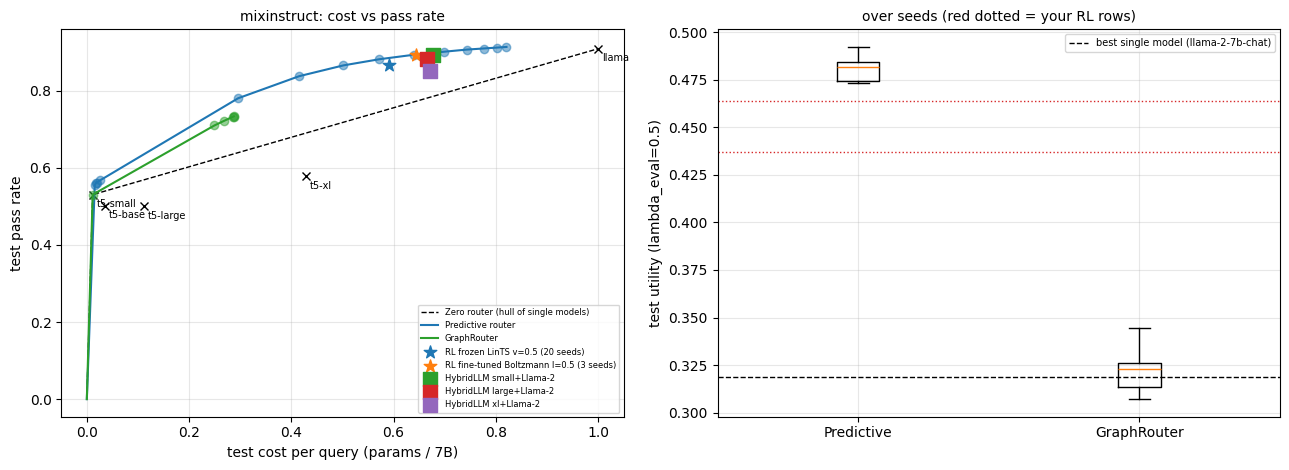

Compute to learn: both learned routers need every model's answer for every training question = 11.1B parameter-calls per training question (same as the FrugalGPT cascade). Your RL router measured 1.8B (MMLU) / 4.4B (MixInstruct), and it only needs feedback on the answer it served.
saved /home/bhavana.ravi/hybridllm_project/outputs/gr_mixinstruct_results.json


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
hz = ndch(zero_points); ax[0].plot([p[0] for p in hz], [p[1] for p in hz], "k--", lw=1, label="Zero router (hull of single models)")
for j in range(K): ax[0].plot(fixed_test[j]["cost"], fixed_test[j]["acc"], "kx"); ax[0].annotate(MODEL_NAMES[j].replace("flan-t5-", "t5-").replace("llama-2-7b-chat", "llama"), (fixed_test[j]["cost"], fixed_test[j]["acc"]), textcoords="offset points", xytext=(3, -9), fontsize=7)
for nm, pts, col in (("Predictive router", curve_p, "tab:blue"), ("GraphRouter", curve_g, "tab:green")):
    h = ndch(pts); ax[0].plot([p[0] for p in pts], [p[1] for p in pts], "o", color=col, alpha=0.5); ax[0].plot([p[0] for p in h], [p[1] for p in h], "-", color=col, label=nm)
for n, c, a, u in OTHERS: ax[0].scatter(c, a, marker="*" if n.startswith("RL") else "s" if n.startswith("Hybrid") else "^", s=90, label=n, zorder=5)
ax[0].set_xlabel("test cost per query (params / 7B)"); ax[0].set_ylabel(f"test {QUALITY_LABEL}"); ax[0].grid(alpha=0.3); ax[0].legend(fontsize=6); ax[0].set_title(f"{DATASET}: cost vs {QUALITY_LABEL}", fontsize=10)
ax[1].boxplot([[e["util"] for e in r_p], [e["util"] for e in r_g]]); ax[1].set_xticklabels(["Predictive", "GraphRouter"])
ax[1].axhline(bf, color="k", ls="--", lw=1, label=f"best single model ({MODEL_NAMES[best_fixed]})")
for n, c, a, u in OTHERS:
    if n.startswith("RL"): ax[1].axhline(u, ls=":", lw=1, color="tab:red")
ax[1].set_ylabel(f"test utility (lambda_eval={LAMBDA_EVAL})"); ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3); ax[1].set_title("over seeds (red dotted = your RL rows)", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, f"gr_{DATASET}_comparison.png"), dpi=150); plt.show()

compute_B = PARAMS.sum() / 1e9
print(f"Compute to learn: both learned routers need every model's answer for every training question = {compute_B:.1f}B parameter-calls per training question "
      f"(same as the FrugalGPT cascade). Your RL router measured 1.8B (MMLU) / 4.4B (MixInstruct), and it only needs feedback on the answer it served.")

out = {"dataset": DATASET, "synthetic": SYNTHETIC_TEST, "n_seeds": N_SEEDS, "aiq": {"zero": aiq(zero_points), "predictive": aiq(curve_p), "graphrouter": aiq(curve_g)},
       "predictive": {"lambda": float(k_p), "test": [{k: float(v) for k, v in e.items() if k != "shares"} for e in r_p], "curve": curve_p},
       "graphrouter": {"lambda": float(k_g), "test": [{k: float(v) for k, v in e.items() if k != "shares"} for e in r_g], "curve": curve_g},
       "best_fixed": MODEL_NAMES[best_fixed], "fixed_test": {MODEL_NAMES[j]: {k: float(v) for k, v in fixed_test[j].items() if k != "shares"} for j in range(K)}}
json.dump(out, open(os.path.join(OUTPUT_DIR, f"gr_{DATASET}_results.json"), "w"), indent=2); print("saved", os.path.join(OUTPUT_DIR, f"gr_{DATASET}_results.json"))

## How to describe this

* **GraphRouter** is the accepted-paper comparison (ICLR 2025). This is a re-implementation on your tables and features, with the simplifications listed in section 4.
* The **predictive router** is the RouterBench-style baseline. It is also what the R2-Router (ICML 2026) quality head becomes when the output-length axis is removed, so do not call it "R2-Router".
* Both learned routers are offline supervised and use every model's answer for every training question. Your RL router is online and uses feedback only for the model it served. Say so when comparing quality.
* HybridLLM and FrugalGPT rows are single runs copied from your deck, so they have no error bars. Seeds here capture learning randomness only.
* Intervals are over 5 seeds. Treat gaps smaller than the seed spread as ties.